## Team
Aden Thompson

Cody Reep

11/13/2026

## Description

In this project, our team loaded the Breast Cancer Wisconsin (Diagnostic) dataset containing 569 entries and 31 features per entry. Each entry specified properties (e.g., radius, compactness, and concavity) about the cell nuclei within one breast tumor tissue sample.

The target feature was the binary ‘Diagnosis’ feature, where ‘M’ indicated the tumor was malignant and ‘B’ indicated that it was benign. The input features are summary statistics about the physical or structural measurements of the cell nuclei within the sample, such as perimeter, texture, and symmetry.

Before training, the ID feature was dropped because it does not provide relevant information. Next, the data was split into a training and testing set using StratifiedShuffleSplit (80/20). Additionally, the Diagnosis feature was encoded into a numerical form using OrdinalEncoder. Last, all input features were scaled using StandardScaler.

We then used sklearn’s logistic regression to predict the target feature (i.e., Diagnosis). On the 455-entry training set, cross-validation (10) testing yielded a 97.00% precision score and 95.29% recall score. On the 114-entry testing set, the model achieved a 97.5% precision score and 92.86% recall score. In addition, for both the training and testing sets, confusion matrices were computed, and ROC curves were plotted.

In [1]:
# Import libraries that are needed to train and test the model
import pandas as pd
from pandas.plotting import scatter_matrix
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.model_selection import StratifiedShuffleSplit, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, confusion_matrix, roc_curve
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt


In [2]:
# Import the dataset
# Get the data
data_path = "https://archive.ics.uci.edu/static/public/17/data.csv"
def load_cancer_data():
    csv_path = data_path
    return pd.read_csv(csv_path, sep=',', low_memory=False)

In [3]:
# Set the cancer variable equal to the pd dataframe provided by the function
cancer = load_cancer_data()

## Inspect Data

In [4]:
# View the info of the cancer dataframe
cancer.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  569 non-null    int64  
 1   radius1             569 non-null    float64
 2   texture1            569 non-null    float64
 3   perimeter1          569 non-null    float64
 4   area1               569 non-null    float64
 5   smoothness1         569 non-null    float64
 6   compactness1        569 non-null    float64
 7   concavity1          569 non-null    float64
 8   concave_points1     569 non-null    float64
 9   symmetry1           569 non-null    float64
 10  fractal_dimension1  569 non-null    float64
 11  radius2             569 non-null    float64
 12  texture2            569 non-null    float64
 13  perimeter2          569 non-null    float64
 14  area2               569 non-null    float64
 15  smoothness2         569 non-null    float64
 16  compactness2       

In [5]:
# View the description of the cancer dataframe
cancer.describe(include="all")

,ID,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,B
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,357
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN


In [6]:
# View the first five observations of the cancer dataframe
cancer.head()

,ID,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
0,842302,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,842517,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,84300903,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,84348301,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,84358402,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


In [7]:
# View the last five observations of the cancer dataframe
cancer.tail()

,ID,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
564,926424,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,M
565,926682,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,M
566,926954,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,M
567,927241,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,M
568,92751,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,B


In [8]:
# Get the shape of the cancer dataframe
cancer.shape

(569, 32)

In [9]:
# Drop the ID feature as it has no useful data in the predictions.
cancer = cancer.drop(["ID",], axis=1)

In [10]:
# View the info of the cancer dataframe after dropping the ID feature
cancer.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             569 non-null    float64
 1   texture1            569 non-null    float64
 2   perimeter1          569 non-null    float64
 3   area1               569 non-null    float64
 4   smoothness1         569 non-null    float64
 5   compactness1        569 non-null    float64
 6   concavity1          569 non-null    float64
 7   concave_points1     569 non-null    float64
 8   symmetry1           569 non-null    float64
 9   fractal_dimension1  569 non-null    float64
 10  radius2             569 non-null    float64
 11  texture2            569 non-null    float64
 12  perimeter2          569 non-null    float64
 13  area2               569 non-null    float64
 14  smoothness2         569 non-null    float64
 15  compactness2        569 non-null    float64
 16  concavity2         

## Visualize the Data

array([[<Axes: xlabel='radius1', ylabel='radius1'>,
        <Axes: xlabel='texture1', ylabel='radius1'>,
        <Axes: xlabel='perimeter1', ylabel='radius1'>,
        <Axes: xlabel='area1', ylabel='radius1'>,
        <Axes: xlabel='smoothness1', ylabel='radius1'>,
        <Axes: xlabel='compactness1', ylabel='radius1'>,
        <Axes: xlabel='concavity1', ylabel='radius1'>,
        <Axes: xlabel='concave_points1', ylabel='radius1'>,
        <Axes: xlabel='symmetry1', ylabel='radius1'>,
        <Axes: xlabel='fractal_dimension1', ylabel='radius1'>],
       [<Axes: xlabel='radius1', ylabel='texture1'>,
        <Axes: xlabel='texture1', ylabel='texture1'>,
        <Axes: xlabel='perimeter1', ylabel='texture1'>,
        <Axes: xlabel='area1', ylabel='texture1'>,
        <Axes: xlabel='smoothness1', ylabel='texture1'>,
        <Axes: xlabel='compactness1', ylabel='texture1'>,
        <Axes: xlabel='concavity1', ylabel='texture1'>,
        <Axes: xlabel='concave_points1', ylabel='texture1'>

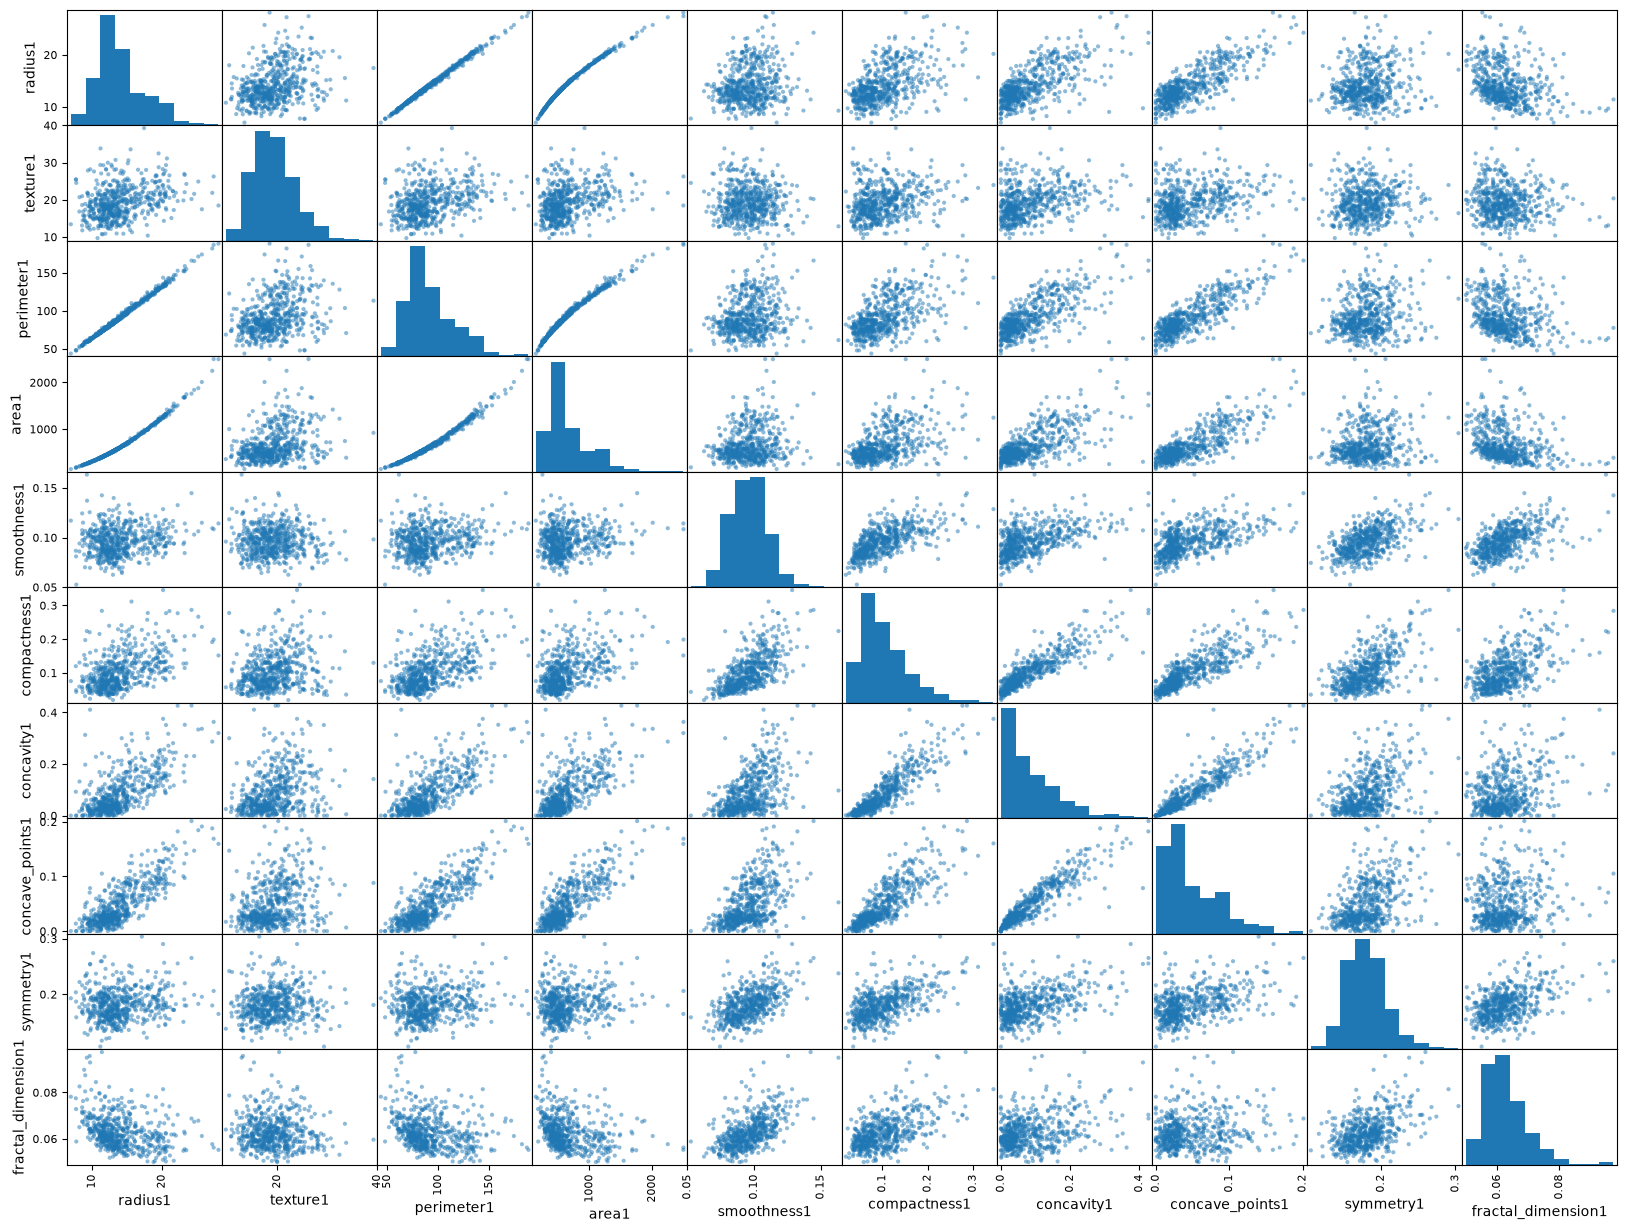

In [11]:
# Create a scatter plot matrix for some of the features
scatter_matrix(cancer[["radius1", "texture1", "perimeter1", "area1", "smoothness1", "compactness1", "concavity1", "concave_points1", "symmetry1", "fractal_dimension1"]], figsize=(20, 15))

## Split the data into test and train sets

In [12]:
# Split the dataset using a stratified split
split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
for train_index, test_index in split.split(cancer, cancer["Diagnosis"]):
    strat_train_set = cancer.loc[train_index]
    strat_test_set = cancer.loc[test_index]

In [13]:
# View the info of the train set
strat_train_set.info()

<class 'pandas.DataFrame'>
Index: 455 entries, 10 to 335
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             455 non-null    float64
 1   texture1            455 non-null    float64
 2   perimeter1          455 non-null    float64
 3   area1               455 non-null    float64
 4   smoothness1         455 non-null    float64
 5   compactness1        455 non-null    float64
 6   concavity1          455 non-null    float64
 7   concave_points1     455 non-null    float64
 8   symmetry1           455 non-null    float64
 9   fractal_dimension1  455 non-null    float64
 10  radius2             455 non-null    float64
 11  texture2            455 non-null    float64
 12  perimeter2          455 non-null    float64
 13  area2               455 non-null    float64
 14  smoothness2         455 non-null    float64
 15  compactness2        455 non-null    float64
 16  concavity2          455

In [14]:
# View the info of the test set
strat_test_set.info()

<class 'pandas.DataFrame'>
Index: 114 entries, 120 to 75
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             114 non-null    float64
 1   texture1            114 non-null    float64
 2   perimeter1          114 non-null    float64
 3   area1               114 non-null    float64
 4   smoothness1         114 non-null    float64
 5   compactness1        114 non-null    float64
 6   concavity1          114 non-null    float64
 7   concave_points1     114 non-null    float64
 8   symmetry1           114 non-null    float64
 9   fractal_dimension1  114 non-null    float64
 10  radius2             114 non-null    float64
 11  texture2            114 non-null    float64
 12  perimeter2          114 non-null    float64
 13  area2               114 non-null    float64
 14  smoothness2         114 non-null    float64
 15  compactness2        114 non-null    float64
 16  concavity2          114

## Preprocess the Data

## Feature scaling and encoding

In [15]:
# Data encoding
# Use the OrdinalEncoder to convert strings into numerical data
cat_encoder = OrdinalEncoder()

# Encode the string data into numerical data for both the train & test set
strat_train_set["Diagnosis"] = cat_encoder.fit_transform(strat_train_set[["Diagnosis"]])
strat_test_set["Diagnosis"] = cat_encoder.fit_transform(strat_test_set[["Diagnosis"]])


In [16]:
# Get the features (columns used in prediction) and the target (what you are trying to predict) from the train set

#Target
# Copy the Diagnosis feature from both the test and train sets
Y_train = strat_train_set["Diagnosis"].copy()
Y_test = strat_test_set["Diagnosis"].copy()

#Features
# Drop the Diagnosis feature from both the test and train sets
strat_train_set = strat_train_set.drop("Diagnosis", axis=1)
strat_test_set = strat_test_set.drop("Diagnosis", axis=1)

In [17]:
#PIPELINE SCALING

# Create a pipeline to scale all features
scaler_pipeline = Pipeline([
        ('std_scaler', StandardScaler()),
    ])

# Run the train set through the scaler pipeline
scaled_train_set = scaler_pipeline.fit_transform(strat_train_set)
# Run the test set through the scaler pipeline
scaled_test_set = scaler_pipeline.transform(strat_test_set)

# Train the model

In [18]:
# Get the LogisticRegressor model for classification
log_reg = LogisticRegression(solver="lbfgs", random_state=42)

# Fit the model to the train set
log_reg.fit(scaled_train_set, Y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

## Evaluation of the Model

In [19]:
# Get the predictions of the model on the train set.
Y_pred = log_reg.predict(scaled_train_set)

In [20]:
# View the Precision, Recall, and Confusion matrix of the model on the train set

# Precision
print(precision_score(Y_train, Y_pred))
# Recall
print(recall_score(Y_train, Y_pred))
# Confusion matrix
confusion_matrix(Y_train, Y_pred)

1.0
0.9647058823529412


array([[285,   0],
       [  6, 164]])

In [21]:
# Function to plot the ROC curve (from the Ch. 3 GitHub notebook)
def plot_roc_curve(fpr, tpr, label=None):
    plt.plot(fpr, tpr, linewidth=2, label=label)
    plt.plot([0, 1], [0, 1], 'k--')
    plt.axis([0, 1, 0, 1])
    plt.xlabel('False Positive Rate (Fall-Out)', fontsize=16)
    plt.ylabel('True Positive Rate (Recall)', fontsize=16)
    plt.grid(True)

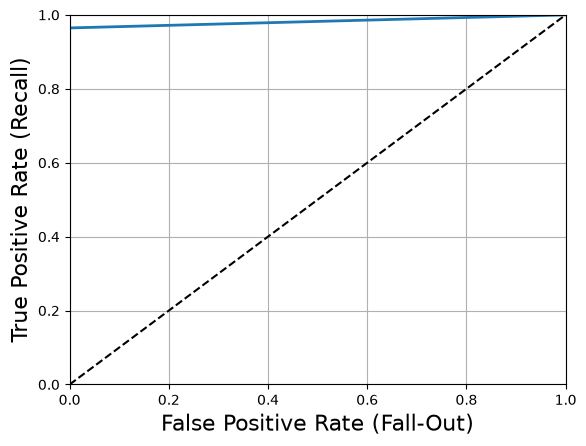

In [22]:
# Plot the ROC curve for the model on the train set
fpr, tpr, thresholds = roc_curve(Y_train, Y_pred)
plot_roc_curve(fpr, tpr)
plt.show()

## Improved Evaluation of the Model

In [23]:
# Get cross-validation predictions for evaluation
Y_cross_pred = cross_val_predict(log_reg, scaled_train_set, Y_train, cv=10)

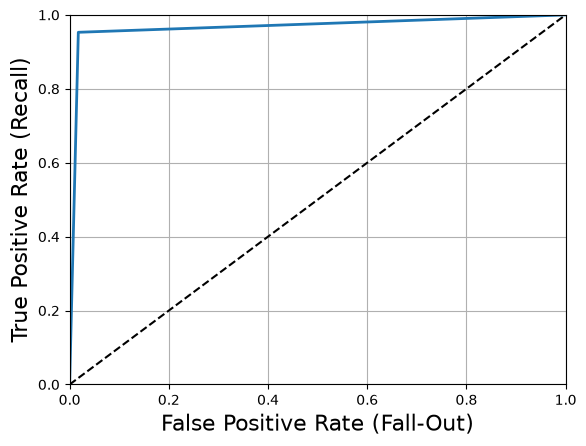

In [24]:
# Plot the ROC curve of the cross-validation
fpr2, tpr2, thresholds = roc_curve(Y_train, Y_cross_pred)
plot_roc_curve(fpr2, tpr2)
plt.show()

In [25]:
# View the Precision, Recall, and Confusion matrix of the model on the train set using cross-validation

# Precision
print(precision_score(Y_train, Y_cross_pred))
# Recall
print(recall_score(Y_train, Y_cross_pred))
# Confusion matrix
confusion_matrix(Y_train, Y_cross_pred)

0.9700598802395209
0.9529411764705882


array([[280,   5],
       [  8, 162]])

## Evaluate the Model on the Test Set

In [26]:
# Get final prediction values to evaluate the model on a test set
final_predictions = log_reg.predict(scaled_test_set)

In [27]:
# View the Precision, Recall, and Confusion matrix of the model on the test set

# Precision
print(precision_score(Y_test, final_predictions))
# Recall
print(recall_score(Y_test, final_predictions))
# Confusion matrix
confusion_matrix(Y_test, final_predictions)

0.975
0.9285714285714286


array([[71,  1],
       [ 3, 39]])

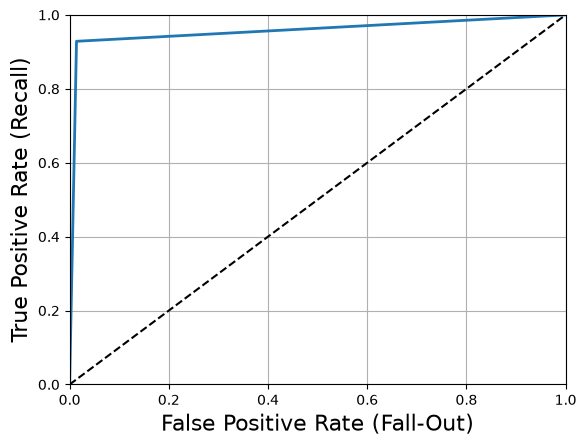

In [28]:
# Plot the ROC curve of the model on the test set
fpr3, tpr3, thresholds = roc_curve(Y_test, final_predictions)
plot_roc_curve(fpr3, tpr3)